<a href="https://colab.research.google.com/github/shoneabraham2028-hub/FCFS/blob/main/Employee_Salary_LLM_ML_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Employee Salary Prediction: LLM-Generated Data + ML Model Tuning
**Courses:** 24BCAT301 Data Science and Machine Learning, 24BCAT351 Generative AI and LLM Application Development

**Plan:** Part A makes data with Llama, Part B builds the model, Part C measures it, Part D tunes it.

**Setup (one time, on your laptop):**
1. Install Ollama from ollama.com
2. In a terminal run: `ollama pull llama3.2`
3. Keep Ollama running, then run this notebook cell by cell.

In [ ]:
!sudo apt-get install -y zstd
!curl -fsSL https://ollama.com/install.sh | sh
import subprocess, time
subprocess.Popen(["ollama", "serve"])
time.sleep(5)
!ollama pull llama3.2

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  zstd
0 upgraded, 1 newly installed, 0 to remove and 33 not upgraded.
Need to get 644 kB of archives.
After this operation, 1,845 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble-updates/main amd64 zstd amd64 1.5.5+dfsg2-2build1.1 [644 kB]
Fetched 644 kB in 1s (439 kB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package zstd.
(Reading database ... 127324 files and directo

In [ ]:
!ollama list

NAME               ID              SIZE      MODIFIED               
llama3.2:latest    a80c4f17acd5    2.0 GB    Less than a second ago    


In [ ]:
!pip install ollama pandas numpy scikit-learn matplotlib seaborn

## Part A: Dataset Generation Using Llama LLM
**GenAI concepts used:** system prompt, role prompting, few-shot example, structured output (CSV), temperature control, output validation (guardrail).

In [ ]:
import ollama
import pandas as pd
import numpy as np

MODEL = "llama3.2"   # Llama model running locally through Ollama

COLUMNS = ["Employee_ID","Age","Gender","Department","Education",
           "Experience","City","Salary","Performance_Rating","Overtime","Job_Level"]

# System prompt + role prompting: tells the LLM who it is and how to answer
SYSTEM_PROMPT = (
    "You are a synthetic HR data generator. "
    "Reply with CSV rows only. No header, no explanation, no markdown, no extra text."
)

def make_prompt(start_id, n):
    # Prompt structure: instruction + rules (context) + few-shot examples + output format
    return f"""Generate {n} rows of a synthetic employee salary dataset.
Columns in this exact order:
{", ".join(COLUMNS)}

Rules:
- Employee_ID: format EMP0001, start at EMP{start_id:04d}, increase by 1 each row
- Age: 21 to 60
- Gender: Male, Female
- Department: IT, HR, Finance, Marketing, Operations, Sales
- Education: Diploma, Bachelor, Master, PhD
- Experience: years of work, 0 to 35, must be realistic for the age
- City: Bangalore, Chennai, Kochi, Mumbai, Delhi, Hyderabad
- Salary: yearly salary in Indian rupees, 250000 to 3000000
- Salary must rise with Experience, Education and Job_Level
- Performance_Rating: whole number 1 to 5
- Overtime: Yes or No
- Job_Level: Junior, Mid, Senior, Manager

Example rows:
EMP0001,24,Female,IT,Bachelor,2,Kochi,420000,3,No,Junior
EMP0002,41,Male,Finance,Master,16,Mumbai,1650000,4,Yes,Manager
EMP0003,33,Female,HR,Bachelor,9,Chennai,780000,4,No,Mid

Output exactly {n} CSV rows and nothing else."""

def generate_batch(start_id, n=25):
    response = ollama.chat(
        model=MODEL,
        messages=[{"role":"system","content":SYSTEM_PROMPT},
                  {"role":"user","content":make_prompt(start_id, n)}],
        options={"temperature":0.8}      # higher temperature = more varied data
    )
    return response["message"]["content"]

# Guardrail: keep only rows that pass format and range checks
RULES = {
    "Gender": ["Male","Female"],
    "Department": ["IT","HR","Finance","Marketing","Operations","Sales"],
    "Education": ["Diploma","Bachelor","Master","PhD"],
    "City": ["Bangalore","Chennai","Kochi","Mumbai","Delhi","Hyderabad"],
    "Overtime": ["Yes","No"],
    "Job_Level": ["Junior","Mid","Senior","Manager"],
}
def is_valid(parts):
    if len(parts) != 11: return False
    r = dict(zip(COLUMNS, [p.strip() for p in parts]))
    try:
        if not (21 <= int(r["Age"]) <= 60): return False
        if not (0 <= float(r["Experience"]) <= 35): return False
        if not (250000 <= float(r["Salary"]) <= 3000000): return False
        if not (1 <= int(r["Performance_Rating"]) <= 5): return False
    except ValueError:
        return False
    return all(r[k] in v for k, v in RULES.items())

TARGET_ROWS = 500
rows = []
attempts = 0
while len(rows) < TARGET_ROWS and attempts < 60:
    attempts += 1
    text = generate_batch(len(rows) + 1)
    for line in text.strip().splitlines():
        parts = line.strip().split(",")
        if is_valid(parts):
            rows.append([p.strip() for p in parts])
    print(f"Batch {attempts}: total valid rows = {len(rows)}")

df_raw = pd.DataFrame(rows[:TARGET_ROWS], columns=COLUMNS)
df_raw["Employee_ID"] = [f"EMP{i:04d}" for i in range(1, len(df_raw)+1)]  # fix any ID mistakes

Batch 1: total valid rows = 22
Batch 2: total valid rows = 49
Batch 3: total valid rows = 76
Batch 4: total valid rows = 96
Batch 5: total valid rows = 118
Batch 6: total valid rows = 137
Batch 7: total valid rows = 165
Batch 8: total valid rows = 180
Batch 9: total valid rows = 206
Batch 10: total valid rows = 230
Batch 11: total valid rows = 251
Batch 12: total valid rows = 277
Batch 13: total valid rows = 302
Batch 14: total valid rows = 327
Batch 15: total valid rows = 350
Batch 16: total valid rows = 378
Batch 17: total valid rows = 407
Batch 18: total valid rows = 423
Batch 19: total valid rows = 450
Batch 20: total valid rows = 476
Batch 21: total valid rows = 508


### A2. Save the dataset as CSV

In [ ]:
df_raw.to_csv("employee_salary_dataset.csv", index=False)
print("Saved employee_salary_dataset.csv with", len(df_raw), "rows")

Saved employee_salary_dataset.csv with 500 rows


### A3. Load the dataset with Pandas

In [ ]:
df = pd.read_csv("employee_salary_dataset.csv")
print(df.shape)
df.head()

(500, 11)


,Employee_ID,Age,Gender,Department,Education,Experience,City,Salary,Performance_Rating,Overtime,Job_Level
0,EMP0001,24,Female,IT,Bachelor,1,Kochi,260000,3,No,Junior
1,EMP0002,38,Male,Marketing,Master,10,Kochi,440000,4,Yes,Senior
2,EMP0003,41,Female,Finance,Bachelor,8,Hyderabad,1000000,5,No,Senior
3,EMP0004,29,Male,Operations,Diploma,5,Delhi,270000,3,Yes,Junior
4,EMP0005,27,Female,Sales,Bachelor,3,Mumbai,360000,2,No,Junior


### Data preparation and quick EDA
**DSML concepts used:** data cleaning, missing values, outliers, descriptive statistics, visualization.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

print(df.info())
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().dropna()

df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Employee_ID         500 non-null    object
 1   Age                 500 non-null    int64 
 2   Gender              500 non-null    object
 3   Department          500 non-null    object
 4   Education           500 non-null    object
 5   Experience          500 non-null    int64 
 6   City                500 non-null    object
 7   Salary              500 non-null    int64 
 8   Performance_Rating  500 non-null    int64 
 9   Overtime            500 non-null    object
 10  Job_Level           500 non-null    object
dtypes: int64(4), object(7)
memory usage: 43.1+ KB
None

Missing values:
 Employee_ID           0
Age                   0
Gender                0
Department            0
Education             0
Experience            0
City                  0
Salary                0
Perfo

,Age,Experience,Salary,Performance_Rating
count,500.000000,500.000000,5.000000e+02,500.000000
mean,34.652000,10.124000,1.270354e+06,3.786000
std,8.506917,6.798313,7.750446e+05,0.751887
min,21.000000,0.000000,2.500000e+05,1.000000
25%,27.750000,5.000000,6.000000e+05,3.000000
50%,34.000000,9.000000,1.100000e+06,4.000000
75%,41.000000,15.000000,1.800000e+06,4.000000
max,55.000000,31.000000,3.000000e+06,5.000000


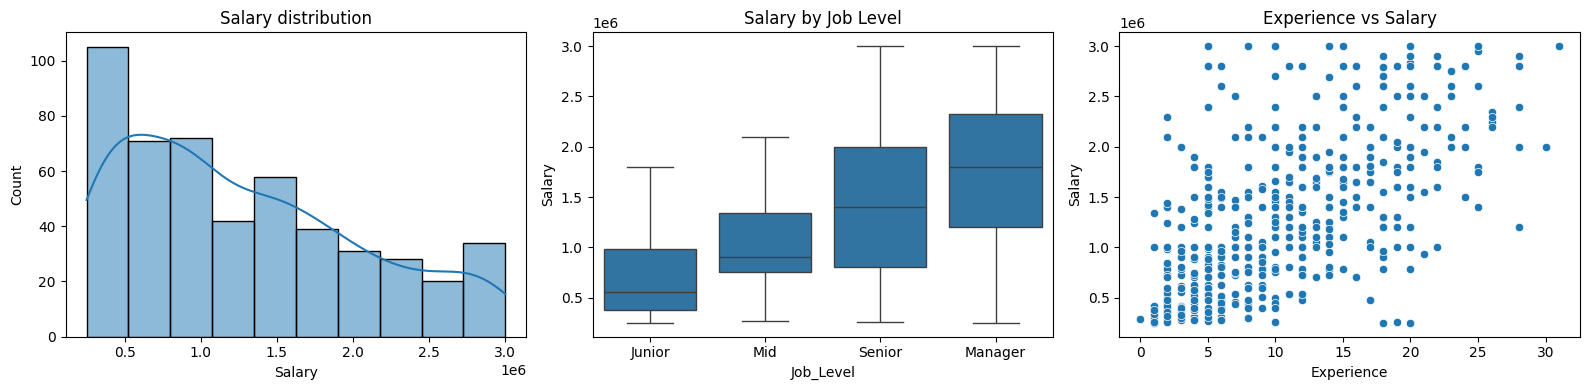

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["Salary"], kde=True, ax=ax[0]); ax[0].set_title("Salary distribution")
sns.boxplot(x="Job_Level", y="Salary", data=df, ax=ax[1],
            order=["Junior","Mid","Senior","Manager"]); ax[1].set_title("Salary by Job Level")
sns.scatterplot(x="Experience", y="Salary", data=df, ax=ax[2]); ax[2].set_title("Experience vs Salary")
plt.tight_layout(); plt.show()

## Part B: Model Development
**Chosen algorithm: Random Forest Classifier.** It handles numbers and categories well, resists overfitting, and has clear hyperparameters to tune.

**Task:** predict Salary_Category (Low, Medium, High). The Salary column is split into 3 equal groups.

In [ ]:
# Turn Salary into a category (classification target)
df["Salary_Category"] = pd.qcut(df["Salary"], q=3, labels=["Low","Medium","High"])
print(df["Salary_Category"].value_counts())

# Drop Employee_ID (just a label) and Salary (it would leak the answer)
X = df.drop(columns=["Employee_ID","Salary","Salary_Category"])
y = df["Salary_Category"]

# Convert text columns to numbers (one-hot encoding)
X = pd.get_dummies(X, drop_first=True)
X.head()

Salary_Category
Low       176
High      166
Medium    158
Name: count, dtype: int64


,Age,Experience,Performance_Rating,Gender_Male,Department_HR,Department_IT,Department_Marketing,Department_Operations,Department_Sales,Education_Diploma,...,Education_PhD,City_Chennai,City_Delhi,City_Hyderabad,City_Kochi,City_Mumbai,Overtime_Yes,Job_Level_Manager,Job_Level_Mid,Job_Level_Senior
0,24,1,3,False,False,True,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False
1,38,10,4,True,False,False,True,False,False,False,...,False,False,False,False,True,False,True,False,False,True
2,41,8,5,False,False,False,False,False,False,False,...,False,False,False,True,False,False,False,False,False,True
3,29,5,3,True,False,False,False,True,False,True,...,False,False,True,False,False,False,True,False,False,False
4,27,3,2,False,False,False,False,False,True,False,...,False,False,False,False,False,True,False,False,False,False


### B2. Split into training and testing sets (80% / 20%)

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Training rows:", X_train.shape[0], "| Testing rows:", X_test.shape[0])

Training rows: 400 | Testing rows: 100


### B3. Train the model (default settings)

In [ ]:
from sklearn.ensemble import RandomForestClassifier

base_model = RandomForestClassifier(random_state=42)
base_model.fit(X_train, y_train)
print("Base model trained.")

Base model trained.


## Part C: Model Performance Evaluation
Metrics: Accuracy, Precision, Recall, F1-score. Weighted average is used because there are 3 classes.

Model        Before tuning
Accuracy              0.64
Precision         0.632058
Recall                0.64
F1-score           0.63479
dtype: object

               precision    recall  f1-score   support

        High       0.73      0.82      0.77        33
         Low       0.68      0.66      0.67        35
      Medium       0.48      0.44      0.46        32

    accuracy                           0.64       100
   macro avg       0.63      0.64      0.63       100
weighted avg       0.63      0.64      0.63       100



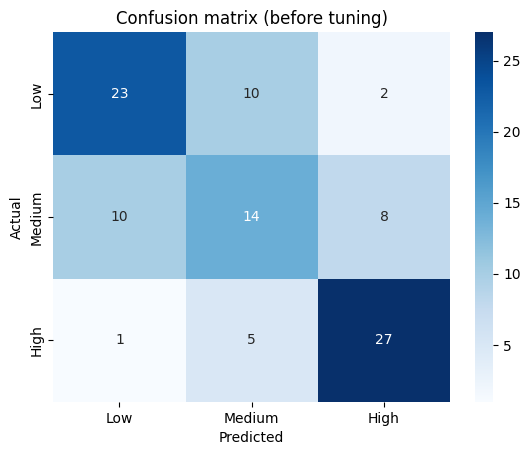

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

def evaluate(model, name):
    pred = model.predict(X_test)
    result = {
        "Model": name,
        "Accuracy":  accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, average="weighted", zero_division=0),
        "Recall":    recall_score(y_test, pred, average="weighted", zero_division=0),
        "F1-score":  f1_score(y_test, pred, average="weighted", zero_division=0),
    }
    return result, pred

base_result, base_pred = evaluate(base_model, "Before tuning")
print(pd.Series(base_result))
print("\n", classification_report(y_test, base_pred, zero_division=0))

labels = ["Low","Medium","High"]
sns.heatmap(confusion_matrix(y_test, base_pred, labels=labels), annot=True, fmt="d",
            cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix (before tuning)")
plt.show()

## Part D: Hyperparameter Tuning
### D1. Important hyperparameters of Random Forest
| Hyperparameter | Meaning |
|---|---|
| n_estimators | Number of trees in the forest |
| max_depth | Maximum depth of each tree (controls overfitting) |
| min_samples_split | Minimum samples needed to split a node |
| min_samples_leaf | Minimum samples needed in a leaf node |

### D2. Cross-validation with Grid Search (5-fold)

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
}

grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid, cv=5, scoring="f1_weighted", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best cross-validation F1:", round(grid.best_score_, 4))

Best parameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 200}
Best cross-validation F1: 0.6285


### D3. Compare performance before and after tuning

In [ ]:
tuned_model = grid.best_estimator_
tuned_result, tuned_pred = evaluate(tuned_model, "After tuning")

comparison = pd.DataFrame([base_result, tuned_result]).set_index("Model").round(4)
print(comparison)

comparison.T.plot(kind="bar", figsize=(8,4))
plt.title("Before vs After Hyperparameter Tuning"); plt.ylim(0, 1.05)
plt.xticks(rotation=0); plt.ylabel("Score"); plt.show()

## Responsible GenAI Check (24BCAT351, Module 5)
Synthetic data can carry bias from the LLM. This check looks at gender and salary.

In [ ]:
print(df.groupby("Gender")["Salary"].mean().round(0))
print()
print(pd.crosstab(df["Gender"], df["Salary_Category"], normalize="index").round(2))

Gender
Female    1071870.0
Male      1395134.0
Name: Salary, dtype: float64

Salary_Category   Low  Medium  High
Gender                             
Female           0.44    0.36  0.21
Male             0.30    0.29  0.41


## Conclusion
- Llama generated 500 validated employee records through a structured prompt with few-shot examples and guardrails.
- A Random Forest classifier predicted salary category, and Accuracy, Precision, Recall and F1-score were measured.
- Grid Search with 5-fold cross-validation found the best hyperparameters, and the results table shows the change in performance.
- **Disclosure:** all data in this project is synthetic, generated by an LLM, and does not describe real people.